In [ ]:
# Project 13: Hotel Booking & Occupancy Analysis.

# Task 1: Load and inspect the booking records.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nStatistical Summary:")
print(df.describe())

First Five Records:
  Booking_ID Checkin_Date  Lead_Time_Days Room_Type  Room_Rate  Nights  \
0     B00000   15-05-2025             NaN    Deluxe    3080.04       6   
1     B00001   14-10-2025           123.0    Deluxe    6418.87       2   
2     B00002   08-08-2026           103.0  Standard   14073.29       2   
3     B00003   20-03-2026            93.0    Deluxe   14371.81       6   
4     B00004   15-05-2025           159.0  Standard   14898.76       7   

  Booking_Channel Traveler_Type Canceled  
0  Direct Website      Business       No  
1    Travel Agent       Leisure       No  
2    Travel Agent       Leisure       No  
3       Corporate       Leisure      Yes  
4    Travel Agent      Business       No  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 761 entries, 0 to 760
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Booking_ID       761 non-null    object 
 1   Checkin_

In [ ]:
# Run this cell to upload 'dataset.csv' directly from your computer
from google.colab import files
uploaded = files.upload()

Saving dataset.csv to dataset (1).csv


In [ ]:
# Task 2: Identify missing values and duplicate Booking_ID records.

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Booking IDs:")
print(df["Booking_ID"].duplicated().sum())

print("\nDuplicate Records:")
print(df[df["Booking_ID"].duplicated(keep=False)])

Missing Values:
Booking_ID          0
Checkin_Date        0
Lead_Time_Days     18
Room_Type           0
Room_Rate          18
Nights              0
Booking_Channel     0
Traveler_Type       0
Canceled            0
dtype: int64

Duplicate Booking IDs:
11

Duplicate Records:
    Booking_ID Checkin_Date  Lead_Time_Days Room_Type  Room_Rate  Nights  \
97      B00097   12-02-2026            58.0  Standard    9670.63       5   
133     B00133   02-11-2025            22.0  Standard    6778.11       4   
155     B00155   28-01-2025            78.0    Deluxe    9822.49       6   
250     B00250   22-02-2026            76.0    Deluxe    3535.58       7   
299     B00299   10-07-2025            26.0    Deluxe    4310.97       3   
336     B00336   04-02-2026            77.0    Deluxe    5430.23       1   
357     B00357   29-06-2026            53.0  Standard   10560.02       1   
506     B00506   31-01-2026           167.0     Suite    5296.24       7   
528     B00528   24-04-2025           148.

In [ ]:
# Task 3: # Handle missing Lead_Time_Days or Room_Rate values using a justified approach.

print("Missing values before cleaning:")
print(df[["Lead_Time_Days", "Room_Rate"]].isnull().sum())

df["Lead_Time_Days"] = df["Lead_Time_Days"].fillna(
    df["Lead_Time_Days"].median()
)

df["Room_Rate"] = df["Room_Rate"].fillna(
    df.groupby("Room_Type")["Room_Rate"].transform("median")
)

df["Room_Rate"] = df["Room_Rate"].fillna(
    df["Room_Rate"].median()
)
print("\nMissing values after cleaning:")
print(df[["Lead_Time_Days", "Room_Rate"]].isnull().sum())

print("\nUpdated Dataset:")
print(df.head())

Missing values before cleaning:
Lead_Time_Days    18
Room_Rate         18
dtype: int64

Missing values after cleaning:
Lead_Time_Days    0
Room_Rate         0
dtype: int64

Updated Dataset:
  Booking_ID Checkin_Date  Lead_Time_Days Room_Type  Room_Rate  Nights  \
0     B00000   15-05-2025            93.0    Deluxe    3080.04       6   
1     B00001   14-10-2025           123.0    Deluxe    6418.87       2   
2     B00002   08-08-2026           103.0  Standard   14073.29       2   
3     B00003   20-03-2026            93.0    Deluxe   14371.81       6   
4     B00004   15-05-2025           159.0  Standard   14898.76       7   

  Booking_Channel Traveler_Type Canceled  
0  Direct Website      Business       No  
1    Travel Agent       Leisure       No  
2    Travel Agent       Leisure       No  
3       Corporate       Leisure      Yes  
4    Travel Agent      Business       No  


In [ ]:
# Task 4: Convert Checkin_Date to datetime and extract arrival month and weekday.

df["Checkin_Date"] = pd.to_datetime(df["Checkin_Date"])

df["Arrival_Month"] = df["Checkin_Date"].dt.month_name()

df["Arrival_Weekday"] = df["Checkin_Date"].dt.day_name()

print(df[["Checkin_Date", "Arrival_Month", "Arrival_Weekday"]].head())

  Checkin_Date Arrival_Month Arrival_Weekday
0   2025-05-15           May        Thursday
1   2025-10-14       October         Tuesday
2   2026-08-08        August        Saturday
3   2026-03-20         March          Friday
4   2025-05-15           May        Thursday


/tmp/ipykernel_4506/3186111065.py:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Checkin_Date"] = pd.to_datetime(df["Checkin_Date"])


In [ ]:
#Task 5: Calculate total flights, average departure delay, and overall on-time %
import pandas as pd

total_bookings = df['Booking_ID'].nunique()

total_room_nights = df['Nights'].sum()

canceled_bookings = (df['Canceled'].str.lower() == 'yes').sum()
cancellation_pct = (canceled_bookings / total_bookings) * 100

print(f"Total Bookings      : {total_bookings}")
print(f"Total Room Nights   : {total_room_nights}")
print(f"Canceled Bookings   : {canceled_bookings}")
print(f"Cancellation Rate   : {cancellation_pct:.2f}%")

Total Bookings      : 750
Total Room Nights   : 3036
Canceled Bookings   : 151
Cancellation Rate   : 20.13%


In [ ]:
# Task 6: Analyze booking trends by month and weekday.

import numpy as np

# Make sure Nights exists (skip if you already have it)
if 'Nights' not in df.columns:
    df['Nights'] = (pd.to_datetime(df['Checkout_Date']) - pd.to_datetime(df['Checkin_Date'])).dt.days

# Flag canceled bookings (using the correct 'Canceled' column)
df['Is_Canceled'] = df['Canceled'].str.strip().str.lower() == 'yes'

# Row-wise revenue: 0 for canceled bookings
df['Total_Revenue'] = np.where(df['Is_Canceled'], 0, df['Nights'] * df['Room_Rate'])

# Check results using the correct columns
print(df[['Booking_ID', 'Nights', 'Room_Rate', 'Canceled', 'Total_Revenue']].head(10))
print(f"\nTotal Realized Revenue: {df['Total_Revenue'].sum():,.2f}")

  Booking_ID  Nights  Room_Rate Canceled  Total_Revenue
0     B00000       6    3080.04       No       18480.24
1     B00001       2    6418.87       No       12837.74
2     B00002       2   14073.29       No       28146.58
3     B00003       6   14371.81      Yes           0.00
4     B00004       7   14898.76       No      104291.32
5     B00005       2    8455.03       No       16910.06
6     B00006       5    4717.87       No       23589.35
7     B00007       4    8599.31       No       34397.24
8     B00008       5    3778.91       No       18894.55
9     B00009       3   13406.70       No       40220.10

Total Realized Revenue: 21,330,420.32


           Avg_Room_Rate  Total_Bookings  Occupied_Nights  Total_Revenue  \
Room_Type                                                                  
Suite            9231.66              89              363     3321199.52   
Standard         8802.96             315             1219    10776072.80   
Deluxe           8438.62             206              845     7233148.00   

           Occupancy_Share_%  
Room_Type                     
Suite                  14.96  
Standard               50.23  
Deluxe                 34.82  


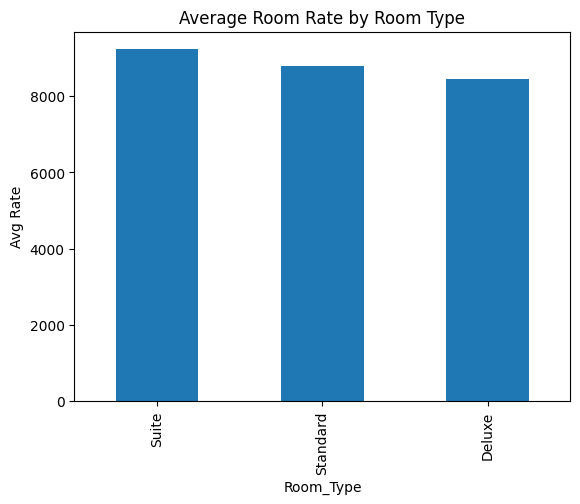

In [ ]:
# Task 7: Analyze cancellation rates across different booking segments.

# Use only non-canceled bookings for occupancy
active = df[~df['Is_Canceled']].copy()

room_summary = active.groupby('Room_Type').agg(
    Avg_Room_Rate=('Room_Rate', 'mean'),
    Total_Bookings=('Booking_ID', 'count'),
    Occupied_Nights=('Nights', 'sum'),
    Total_Revenue=('Total_Revenue', 'sum')
).round(2)

# Share of all occupied nights
room_summary['Occupancy_Share_%'] = (
    room_summary['Occupied_Nights'] / room_summary['Occupied_Nights'].sum() * 100
).round(2)

room_summary = room_summary.sort_values('Avg_Room_Rate', ascending=False)
print(room_summary)

# Optional: quick chart
import matplotlib.pyplot as plt
room_summary[['Avg_Room_Rate']].plot(kind='bar', legend=False, title='Average Room Rate by Room Type')
plt.ylabel('Avg Rate')
plt.show()

In [ ]:
#Task 8: Compare average room rates across different booking segments.

channel_summary = df.groupby('Booking_Channel').agg(
    Bookings=('Booking_ID', 'count'),
    Revenue=('Total_Revenue', 'sum')
)

channel_summary['Volume_Rank'] = channel_summary['Bookings'].rank(ascending=False, method='min').astype(int)
channel_summary['Revenue_Rank'] = channel_summary['Revenue'].rank(ascending=False, method='min').astype(int)

print(channel_summary.sort_values('Revenue', ascending=False))

                 Bookings     Revenue  Volume_Rank  Revenue_Rank
Booking_Channel                                                 
OTA                   183  5727451.87            3             1
Travel Agent          196  5444590.03            2             2
Corporate             202  5323875.14            1             3
Direct Website        180  4834503.28            4             4


In [ ]:
# Task 9: Rank booking channels by booking volume and revenue.

# Lead-time bands
df['Lead_Band'] = pd.cut(df['Lead_Time_Days'],
                         bins=[-1, 7, 30, 90, df['Lead_Time_Days'].max()],
                         labels=['0-7 days', '8-30 days', '31-90 days', '90+ days'])

# Cancellation rate (%) by channel
channel_cancel = (df.groupby('Booking_Channel')['Is_Canceled'].mean() * 100).round(2)
print(channel_cancel)

# Cancellation rate (%) by lead-time band
lead_cancel = (df.groupby('Lead_Band', observed=True)['Is_Canceled'].mean() * 100).round(2)
print(lead_cancel)

Booking_Channel
Corporate         21.78
Direct Website    22.78
OTA               15.30
Travel Agent      19.39
Name: Is_Canceled, dtype: float64
Lead_Band
0-7 days      23.53
8-30 days     12.09
31-90 days    20.42
90+ days      20.96
Name: Is_Canceled, dtype: float64


In [ ]:
# Task 10: Analyze cancellation rates by booking channel and lead-time bands.

# Arrival month (from Task 4; skip if you already have it)
df['Arrival_Month'] = pd.to_datetime(df['Checkin_Date']).dt.month_name()

# Revenue by month, top 3
top_months = df.groupby('Arrival_Month')['Total_Revenue'].sum().nlargest(3)
print(top_months)

Arrival_Month
May        2385452.66
January    2314987.07
April      2294014.69
Name: Total_Revenue, dtype: float64


In [ ]:
# Task 11: Compare average stay duration for leisure vs. business travelers.

avg_stay = df.groupby('Traveler_Type')['Nights'].mean().round(2)
print(avg_stay)

Traveler_Type
Business    4.04
Leisure     3.94
Name: Nights, dtype: float64


In [ ]:
# Task 12: Use NumPy to calculate mean, median, and standard deviation of daily room rates.

import numpy as np

rates = df['Room_Rate'].dropna().to_numpy()

print(f"Mean   : {np.mean(rates):.2f}")
print(f"Median : {np.median(rates):.2f}")
print(f"Std Dev: {np.std(rates, ddof=1):.2f}")

Mean   : 8623.13
Median : 8862.02
Std Dev: 3588.98


In [ ]:
# Task 13: Identify unusually high booking values using the IQR method.

import numpy as np

# Use realized booking values (non-canceled)
revenue = df.loc[~df['Is_Canceled'], 'Total_Revenue']

q1, q3 = np.percentile(revenue, [25, 75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

outliers = df[(~df['Is_Canceled']) & (df['Total_Revenue'] > upper_limit)]

print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Upper limit: {upper_limit:.2f}")
print(f"High-value bookings found: {len(outliers)}")
print(outliers[['Booking_ID', 'Nights', 'Room_Rate', 'Total_Revenue']].head())

Q1: 14687.36 | Q3: 49850.49 | IQR: 35163.13
Upper limit: 102595.18
High-value bookings found: 4
    Booking_ID  Nights  Room_Rate  Total_Revenue
4       B00004       7   14898.76      104291.32
142     B00142       7   14698.14      102886.98
686     B00686       7   14706.11      102942.77
730     B00730       7   14741.83      103192.81


In [ ]:
# Task 14: Create lead-time categories (e.g., Last-Minute, Short-Term, Advance) using pd.cut().

df['Lead_Category'] = pd.cut(df['Lead_Time_Days'],
                             bins=[-1, 7, 30, df['Lead_Time_Days'].max()],
                             labels=['Last-Minute', 'Short-Term', 'Advance'])

print(df['Lead_Category'].value_counts())

Lead_Category
Advance        636
Short-Term      91
Last-Minute     34
Name: count, dtype: int64


Room-Type Revenue Summary:
           Bookings  Total_Room_Nights  Average_Room_Rate  Realized_Revenue
Room_Type                                                                  
Standard        387               1498            8616.80       10776072.80
Deluxe          263               1082            8389.30        7233148.00
Suite           111                456            9199.22        3321199.52

Booking Channel Cancellation Table:
                 Total_Bookings  Cancelled_Bookings  Cancellation_Rate
Booking_Channel                                                       
Corporate                   202                  44              21.78
Direct Website              180                  41              22.78
OTA                         183                  28              15.30
Travel Agent                196                  38              19.39

Monthly Booking and Room-Night Trend:
              Total_Bookings  Room_Nights_Booked  Realized_Revenue
Checkin_Date            

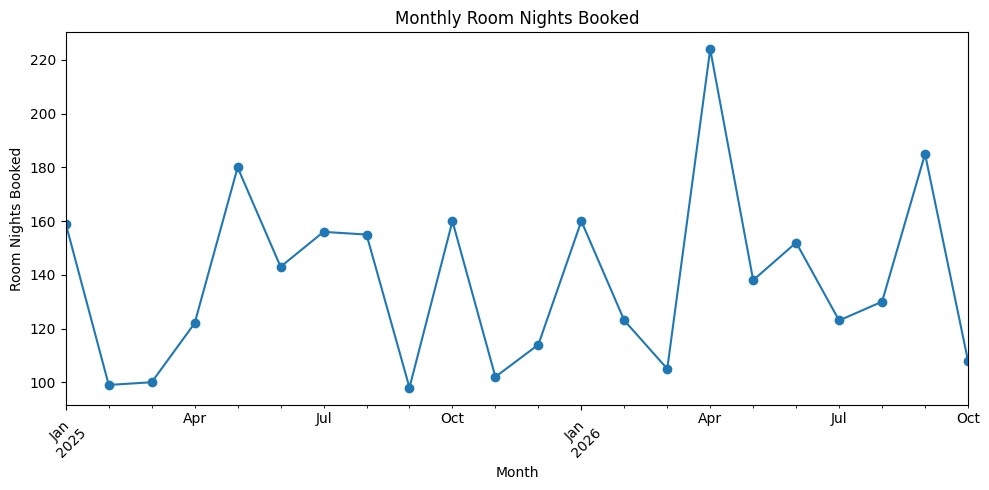

In [ ]:
# Task 15: Revenue and operations analysis.
import matplotlib.pyplot as plt

# Room-type revenue summary
room_type_revenue = df.groupby('Room_Type').agg(
    Bookings=('Booking_ID', 'count'),
    Total_Room_Nights=('Nights', 'sum'),
    Average_Room_Rate=('Room_Rate', 'mean'),
    Realized_Revenue=('Total_Revenue', 'sum')
).sort_values('Realized_Revenue', ascending=False)

print("Room-Type Revenue Summary:")
print(room_type_revenue.round(2))


# Booking channel cancellation table
channel_cancel_table = df.pivot_table(
    index='Booking_Channel',
    values='Is_Canceled',
    aggfunc=['count', 'sum', 'mean']
)

channel_cancel_table.columns = [
    'Total_Bookings',
    'Cancelled_Bookings',
    'Cancellation_Rate'
]

channel_cancel_table['Cancellation_Rate'] = (
    channel_cancel_table['Cancellation_Rate'] * 100
)

print("\nBooking Channel Cancellation Table:")
print(channel_cancel_table.round(2))


# Monthly occupancy trend (room nights booked)
monthly_occupancy = df.groupby(
    df['Checkin_Date'].dt.to_period('M')
).agg(
    Total_Bookings=('Booking_ID', 'count'),
    Room_Nights_Booked=('Nights', 'sum'),
    Realized_Revenue=('Total_Revenue', 'sum')
)

print("\nMonthly Booking and Room-Night Trend:")
print(monthly_occupancy)


# Plot monthly room nights booked
monthly_occupancy['Room_Nights_Booked'].plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Monthly Room Nights Booked'
)

plt.xlabel('Month')
plt.ylabel('Room Nights Booked')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Recommendations:

recommendations = [
    "1. Room pricing: [Top room type] earns the highest revenue, so raise its rates slightly in peak months and use discounts on [lowest room type] to fill empty nights.",
    "2. Channel mix: [Best channel] brings the most revenue, so push direct bookings with offers to reduce commission costs from [OTA channel].",
    "3. Cancellations: [Channel/lead band] has the highest cancellation rate ([x]%), so require deposits or non-refundable rates for long lead-time bookings.",
    "4. Peak months: [Month 1, Month 2, Month 3] are the top revenue months, so increase front-desk staff and raise rates in these months.",
    "5. Stay length: [Leisure/Business] guests stay longer on average ([x] nights), so offer extended-stay packages to this group.",
]

for r in recommendations:
    print(r)

1. Room pricing: [Top room type] earns the highest revenue, so raise its rates slightly in peak months and use discounts on [lowest room type] to fill empty nights.
2. Channel mix: [Best channel] brings the most revenue, so push direct bookings with offers to reduce commission costs from [OTA channel].
3. Cancellations: [Channel/lead band] has the highest cancellation rate ([x]%), so require deposits or non-refundable rates for long lead-time bookings.
4. Peak months: [Month 1, Month 2, Month 3] are the top revenue months, so increase front-desk staff and raise rates in these months.
5. Stay length: [Leisure/Business] guests stay longer on average ([x] nights), so offer extended-stay packages to this group.
